In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

In [3]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
from tqdm import tqdm
import matplotlib.pyplot as plt
import xgboost, lightgbm, catboost

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import config as cnf 
import utils as utl

In [90]:
nn_model = nn.Sequential(
            nn.Linear(X.shape[1], 256),
            nn.BatchNorm1d(num_features=256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.BatchNorm1d(num_features=128),
            nn.ReLU(),
            nn.Linear(128, 2), 
         )

loss_model = nn.CrossEntropyLoss()
opt = torch.optim.Adam(nn_model.parameters(), lr=1e-5)

In [94]:
EPOCHS = 2000

df_train = pd.read_csv(cnf.path['train_path'])

# Обработка данных
df_train_priz = df_train[['Survived', 'Pclass', 'Age', 'Sex',  'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
df_train_priz['Age'] = df_train_priz['Age'].fillna(df_train_priz['Age'].median())
df_train_priz['Embarked'] = df_train_priz['Embarked'].fillna('S')

for col in ['Sex', 'Embarked']:
    df_train_priz[col] = df_train_priz[col].astype('category')

X = df_train_priz.drop('Survived', axis=1)
X = pd.get_dummies(X, dtype=float, drop_first=True)
y = df_train_priz['Survived']

results = []
SK_Fold = StratifiedKFold(n_splits=2, shuffle=True, random_state=cnf.random_state)

model = nn_model


for i, (train_index, test_index) in enumerate(SK_Fold.split(X, y)):
    current_X_train = X.iloc[train_index]
    current_y_train = y.iloc[train_index]
    current_X_test  = X.iloc[test_index]
    current_y_test  = y.iloc[test_index]
    
    scaler = StandardScaler()
    scaler.fit(current_X_train)
    current_X_train = scaler.transform(current_X_train)
    current_X_test = scaler.transform(current_X_test)
    
    tensor_current_X_train = torch.tensor(current_X_train, dtype=torch.float32)
    tensor_current_X_test  = torch.tensor(current_X_test,  dtype=torch.float32)
    tensor_current_y_train = torch.tensor(current_y_train.values, dtype=torch.long)
    tensor_current_y_test  = torch.tensor(current_y_test.values,  dtype=torch.long)
    
    
    
train_loop = tqdm(range(EPOCHS))   
for epoch in train_loop:
    
    model.train()
    pred = model(tensor_current_X_train)
    loss = loss_model(pred, tensor_current_y_train)
    
    opt.zero_grad()
    loss.backward()
    
    opt.step()
    
    model.eval()
    
    with torch.no_grad():
        pred_train = model(tensor_current_X_train)
        pred_test = model(tensor_current_X_test)
        
        loss_train = loss_model(pred_train, tensor_current_y_train)
        loss_test = loss_model(pred_test, tensor_current_y_test)
    
        train_loss = loss_train.item()
        true_answer = (pred_train.argmax(dim=1) == tensor_current_y_train).sum().item()
        train_accuracy = true_answer / len(tensor_current_X_train)
        
        test_loss = loss_test.item()
        true_answer = (pred_test.argmax(dim=1) == tensor_current_y_test).sum().item()
        test_accuracy = true_answer / len(tensor_current_X_test)
        
    train_loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}], train_loss={train_loss}, train_accuracy={train_accuracy}, test_loss={test_loss} test_accuracy={test_accuracy}")


    results.append({
            'epoch'         :   epoch
        , 'train_accuracy'  :   train_accuracy
        , 'train_loss'      :   train_loss
        , 'test_accuracy'   :   test_accuracy
        , 'test_loss'       :   test_loss
    })

Epoch [2000/2000], train_loss=0.23126551508903503, train_accuracy=0.9103139013452914, test_loss=0.5067933797836304 test_accuracy=0.7932584269662921: 100%|██████████| 2000/2000 [00:11<00:00, 172.71it/s] 


In [92]:
results = pd.DataFrame(results)
results

,epoch,train_accuracy,train_loss,test_accuracy,test_loss
0,0,0.405830,0.696615,0.408989,0.692430
1,1,0.405830,0.697360,0.417978,0.693106
2,2,0.412556,0.697773,0.433708,0.693446
3,3,0.410314,0.698351,0.433708,0.693806
4,4,0.410314,0.699174,0.431461,0.694283
...,...,...,...,...,...
1995,1995,0.881166,0.310626,0.820225,0.424067
1996,1996,0.881166,0.310576,0.820225,0.424095
1997,1997,0.881166,0.310526,0.820225,0.424122
1998,1998,0.881166,0.310475,0.817978,0.424148


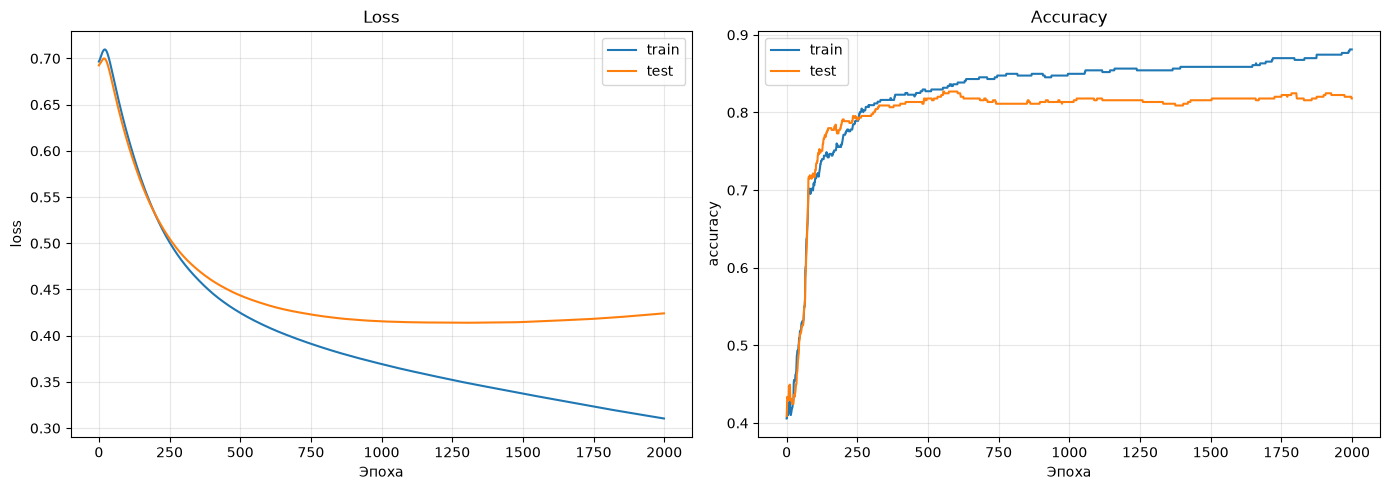

In [93]:
# усредняем по фолдам (для одного фолда значения просто остаются как есть)
curve = results.groupby('epoch').mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(curve.index, curve['train_loss'], label='train')
axes[0].plot(curve.index, curve['test_loss'],  label='test')
axes[0].set_title('Loss')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(curve.index, curve['train_accuracy'], label='train')
axes[1].plot(curve.index, curve['test_accuracy'],  label='test')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()